# sklearn

实例化，建立评估模型对象 （实例化时需要使用的参数）——>通过模型接口训练模型  （数据属性，数据接口）——>通过模型接口提取需要的信息  （数据属性，数据接口）

In [1]:
from cProfile import label

#在这个流程下，分类树对应的代码是
from sklearn import tree  #导入需要模块

clf=tree.DecisionTreeClassifier() #实例化
clf.fit(X_train,y_train) #用训练集数据训练模型
result=clf.score(x_test,y_test) #导入测试集，从接口中调用需要的信息

NameError: name 'X_train' is not defined

## DecisionTreeClassifier 决策树
### 重要参数
#### criterion
对分类树来说，衡量最佳节点和最佳分枝方法的指标叫“不纯度”。通常不纯度越低，决策树对训练集的拟合越好。

不纯度基于节点计算，树中每个节点都会有一个不纯度，并且子节点的不纯度一定是低于父节点的，也就是说，在同一决策树中，叶子结点的不纯度一定是最低的。

criterion这个参数正是用来决定不纯度的计算方法的。sklearn提供了两种：
（1）entropy信息熵
（2）gini基尼系数

在实际使用中，信息熵和基尼系数的效果基本相同

In [2]:
#建立一棵树
#导入所需的模块
from sklearn import tree
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split


In [3]:
#导入数据(葡萄酒数据集)
wine=load_wine()
wine

{'data': array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
         1.065e+03],
        [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
         1.050e+03],
        [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
         1.185e+03],
        ...,
        [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
         8.350e+02],
        [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
         8.400e+02],
        [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
         5.600e+02]], shape=(178, 13)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [4]:
#特征
wine.data

array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
        1.185e+03],
       ...,
       [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
        8.350e+02],
       [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
        8.400e+02],
       [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
        5.600e+02]], shape=(178, 13))

In [5]:
#标签
wine.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2])

In [5]:
import pandas as pd
pd.concat([pd.DataFrame(wine.data),pd.DataFrame(wine.target)],axis=1)

,0,1,2,3,4,5,6,7,8,9,10,11,12,0
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


In [6]:
#特征名
wine.feature_names

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

In [7]:
#标签名
wine.target_names

array(['class_0', 'class_1', 'class_2'], dtype='<U7')

In [8]:
Xtrain,Xtest,Ytrain,Ytest=train_test_split(wine.data,wine.target,test_size=0.3)

In [9]:
#训练集（124行，13个标签）
Xtrain.shape

(124, 13)

In [10]:
#原本的数据(178行，13个标签)
wine.data.shape

(178, 13)

In [11]:
#建模
clf=tree.DecisionTreeClassifier(criterion="entropy",random_state=30) #实例化 random_state随机种子，可固定随机结果
clf=clf.fit(Xtrain,Ytrain) #训练模型
score=clf.score(Xtest,Ytest) #使用接口导出所需分数

In [12]:
score #精确度

0.9444444444444444

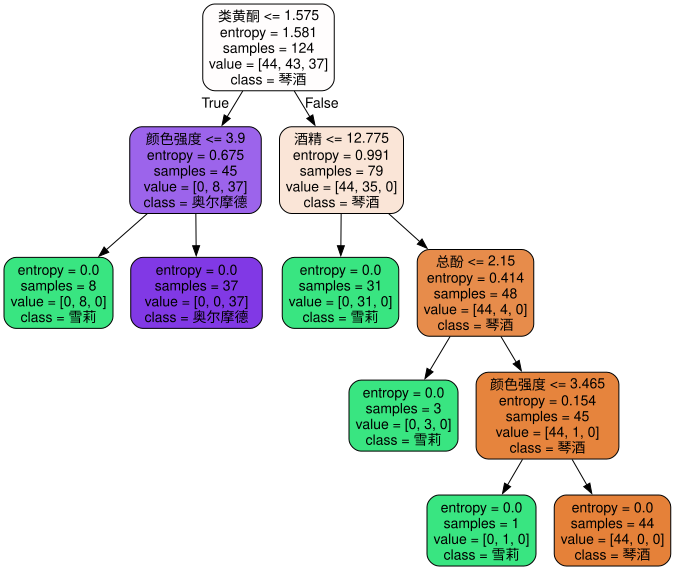

In [13]:
#画图
from sklearn import tree
feature_name=['酒精','苹果酸','灰','灰的碱性','镁','总酚','类黄酮','非黄烷类酚类','花青素','颜色强度','色调','od280/od315稀释葡萄酒','脯氨酸']

import graphviz
dot_data=tree.export_graphviz(clf,
                              feature_names=feature_name,class_names=['琴酒','雪莉','奥尔摩德'],
                              filled=True,rounded=True)
graph=graphviz.Source(dot_data)
graph

In [14]:
clf.feature_importances_
#特征重要度，决策树给每一个特征打的分数，总和=1
#数字越大，这个特征对判断葡萄酒分类越重要；0对特征不起作用

array([0.29789679, 0.        , 0.        , 0.        , 0.        ,
       0.06603613, 0.44577612, 0.        , 0.        , 0.19029096,
       0.        , 0.        , 0.        ])

In [15]:
[*zip(feature_name,clf.feature_importances_)]

[('酒精', np.float64(0.29789679020375703)),
 ('苹果酸', np.float64(0.0)),
 ('灰', np.float64(0.0)),
 ('灰的碱性', np.float64(0.0)),
 ('镁', np.float64(0.0)),
 ('总酚', np.float64(0.06603612787007934)),
 ('类黄酮', np.float64(0.44577611883560103)),
 ('非黄烷类酚类', np.float64(0.0)),
 ('花青素', np.float64(0.0)),
 ('颜色强度', np.float64(0.1902909630905627)),
 ('色调', np.float64(0.0)),
 ('od280/od315稀释葡萄酒', np.float64(0.0)),
 ('脯氨酸', np.float64(0.0))]

#### random_state & splitter
random_state用来设置分枝中的随机模式的参数，默认None。

splitter也是用来控制决策树中的随即选项的，有两种输入值，输入“best”，决策树在分枝时虽然随机，但会优先选择更重要的特征进行分枝；输入“random”，决策树在分枝时会更随机，树会更深，对训练集的拟合会降低。

In [16]:
clf=tree.DecisionTreeClassifier(criterion="entropy",
                                random_state=30,
                                splitter="random")
clf=clf.fit(Xtrain,Ytrain)
score=clf.score(Xtest,Ytest)
score

0.9629629629629629

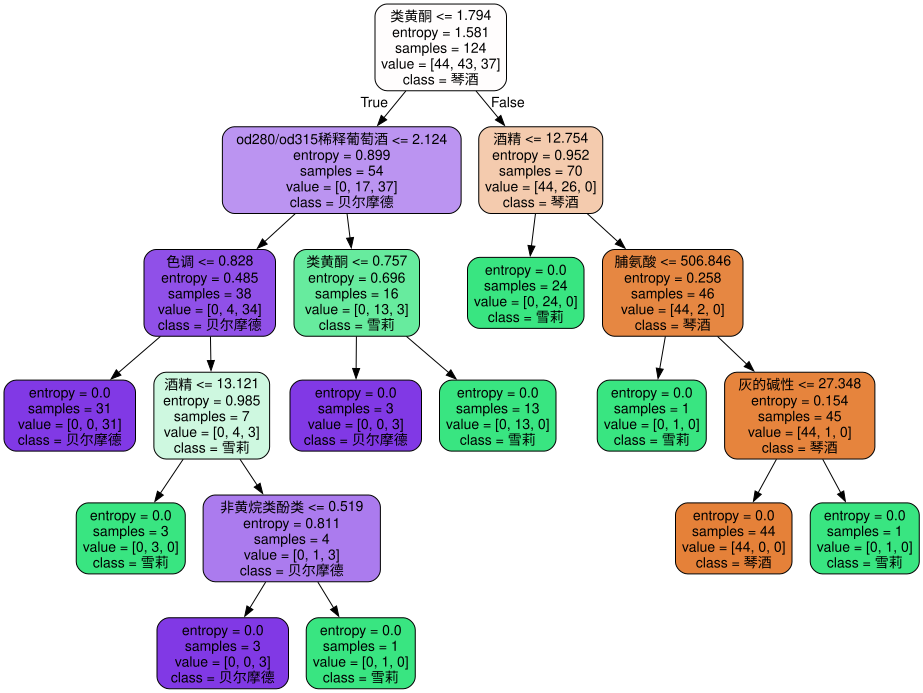

In [17]:
import graphviz
dot_data=tree.export_graphviz(clf,
                              feature_names=feature_name,
                              class_names=['琴酒','雪莉','贝尔摩德'],
                              filled=True,
                              rounded=True)
graph=graphviz.Source(dot_data)
graph

#### 剪枝参数
剪枝：防止决策树过拟合，树不要长的太复杂。这就是说，它会在训练集上表现得很好，在测试集上却表现糟糕。分预剪枝（训练时就限制）、后剪枝（树建好之后再裁剪）。

为了让决策树有更好的泛化性，我们要对决策树进行剪枝。剪枝策略对决策树的影响巨大，正确的剪枝策略是优化策略树算法的核心。sklearn为我们提供了不同的剪枝策略：

##### max_depth
限制树的最大深度，超过设定深度的树枝全部剪掉。

这是用得最广泛的剪枝参数，在高维度低样本量时非常有效。决策树多长一层，对样本量的需求会增加一倍，所以限制树深度能够有效限制拟合。在集成算法中也非常实用。

##### min_samples_leaf & min_samples_split
min_samples_leaf限定，一个节点在分枝后的每个子节点都必须包含至少min_samples_leaf个训练样本量，否则分枝就不会发生，或者分枝会朝着满足每个子节点都包含min_samples_leaf个样本的方向去发生。

一般搭配max_depth使用，可以让模型变得更加平滑。这个参数的数量设置太小会引起过拟合，太大会阻止模型学习数据。

min_samples_split限定，一个节点必须包含至少min_samples_split个训练样本，这个节点才允许被分枝，否则分枝不会发生

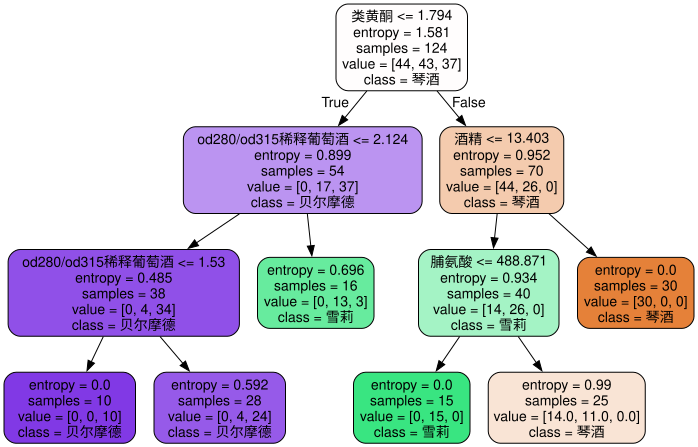

In [18]:
clf=tree.DecisionTreeClassifier(criterion="entropy",
                                random_state=30,
                                splitter="random",
                                max_depth=3,
                                min_samples_leaf=10,
                                min_samples_split=10)
clf=clf.fit(Xtrain,Ytrain)
dot_data=tree.export_graphviz(clf,
                              feature_names=feature_name,
                              class_names=['琴酒','雪莉','贝尔摩德'],
                              filled=True,
                              rounded=True)
graph=graphviz.Source(dot_data)
graph

In [19]:
score=clf.score(Xtest,Ytest)
score

0.7777777777777778

#### max_features & min_impurity_decrease
一般max_depth使用，用作树的“精修”。

max_features限制分枝时考虑的特征个数，超过限制个数的特征都会被舍弃。强行设置可能导致模型学习不足。

min_impurity_decrease限制信息增益的大小，信息增益小于设定数值的分枝不会发生。

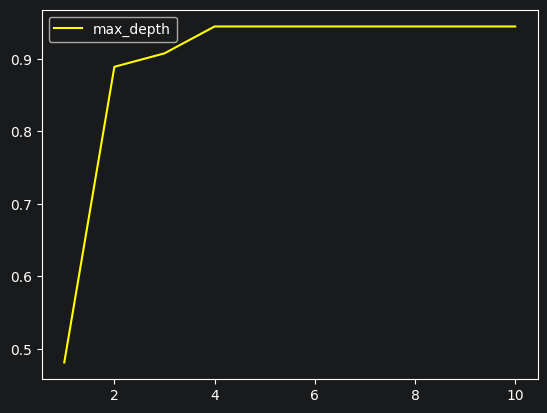

In [20]:
import matplotlib.pyplot as plt

test=[]
for i in range(10):
    clf=tree.DecisionTreeClassifier(max_depth=i+1,criterion="entropy",random_state=30)
    clf=clf.fit(Xtrain,Ytrain)
    score=clf.score(Xtest,Ytest)
    test.append(score)
plt.plot(range(1,11),test,color='yellow',label='max_depth')
plt.legend()
plt.show()

### 重要属性和接口
属性是在模型训练之后，能调用查看的模型的各种性质。

sklearn中许多算法的接口是相似的。

In [21]:
# apply返回每个测试样本所在的叶子节点的索引
clf.apply(Xtest)

array([10,  5, 10, 10,  3,  5,  5,  5,  5, 10,  3,  3, 10,  3,  5,  9,  2,
        5,  3, 10,  5,  5,  5,  3, 10,  9,  5, 10,  3, 10,  5,  2,  3,  5,
        5,  7, 10, 10,  2, 10,  2,  3, 10, 10, 10,  2,  5,  5,  5,  2, 10,
        3,  3,  5])

In [22]:
#predict返回每个测试样本的分类/回归结果(返回标签)
clf.predict(Xtest)

array([0, 1, 0, 0, 2, 1, 1, 1, 1, 0, 2, 2, 0, 2, 1, 1, 1, 1, 2, 0, 1, 1,
       1, 2, 0, 1, 1, 0, 2, 0, 1, 1, 2, 1, 1, 1, 0, 0, 1, 0, 1, 2, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 2, 2, 1])

##### 总结
七个参数：criterion,两个随机性相关的参数（random_state,splitter）,四个剪枝参数（max_depth,min_sample_leaf,max_feature,min_impurity_decrease）

一个属性：feature_importances_

四个接口：fit,score,apply,predict

## 随机森林在sklearn中的实现
### 概述
#### 集成算法概述
集成学习本身不是一个单独的机器学习算法，而是通过在数据上构建多个模型，集成所有模型的建模结果。

集成算法会考虑多个评估器的建模成果，汇总后得到一个综合结果，以此来获取比单个模型更好的回归或分类表现。

多个模型集成成为的模型叫集成评估器，组成集成评估器的每个模型都叫基评估器。通常有三类集成算法：装袋法（bagging，模型独立，互相平行），提升法（boosting，模型有序，逐渐提升）和stacking。

袋装法的核心思想是构建多个互相独立的评估器，然后对其预测进行平均或多数表决原则来决定集成评估器的结果。袋装法的代表模型是随机森林。

提升法中，基评估器是相关的，是按顺序一一构建的，其核心思想是结合弱评估器的力量一次次对难以评估的样本进行预测，从而构成一个强评估器。提升法的代表模型有Adaboost和梯度提升树。

In [25]:
# 随机森林的基本流程
from sklearn.tree import RandomForestClassifier #导入需要的模块

rfc=RandomForestClassifie() #实例化
rfc=rfc.fit(X_train,y_train) #用训练集数据训练模型
result=rfc.score(Xtest,y_test) #导入测试集，从接口中调用需要的信息

ImportError: cannot import name 'RandomForestClassifier' from 'sklearn.tree' (D:\Python\Python3.14\Lib\site-packages\sklearn\tree\__init__.py)

### RandomForestClassifier（随机森林分类器）
随机森林是非常具有代表性的bagging集成算法，它所有基评估器都是决策树，分类树组成的森林就叫随机森林分类器，回归树所集成的森林就叫随机森林回归器。
#### 重要参数
##### 控制基评估器的参数
criterion：不纯度的衡量指标，有基尼系数和信息熵两种选择。

max_depth：树的最大深度，超过最大深度的树枝都会被剪掉。

min_samples_leaf：一个节点在分枝后的每个子节点都必须包含至少min_samples_leaf个训练样本，否则分枝就不会发生。

min_samples_split：一个节点必须要包含至少min_samples_split个训练样本，这个节点才允许被分枝，否则分枝就不会发生。

max_features：max_features：限制分枝时考虑的特征个数，超过限制个数的特征都会被舍弃，默认值为总特征个数开平方取整。

min_impurity_decrease：限制信息增益的大小，信息增益小于设定数值的分枝不会发生。

##### n_estimators
这是森林中树木的数量，即基评估器的数量，这个参数对随机森林模型的精确性影响是单调的，n_estimators 越大，模型的效果往往越好，但是相应的，任何模型都有决策边界，n_estimators达到一定的程度之后，随机森林的精谁性往往不在上升或开始波动，并且，n_estimators越大，需要的计算量和内存也越大，训练的时间也会越来越长。

In [23]:
#导入数据库
%matplotlib inline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_wine

In [24]:
#导入数据集
wine=load_wine()
wine.data #特征

array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
        1.185e+03],
       ...,
       [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
        8.350e+02],
       [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
        8.400e+02],
       [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
        5.600e+02]], shape=(178, 13))

In [25]:
wine.target #标签

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2])

In [26]:
# 导入训练集和测试集模块
from sklearn.model_selection import train_test_split
Xtrain,Xtest,Ytrain,Ytest=train_test_split(wine.data,wine.target,test_size=0.3) #70%训练集，30%测试集

In [27]:
#建模

#实例化
clf=DecisionTreeClassifier(random_state=0)
rfc=RandomForestClassifier(random_state=0)

#训练
clf=clf.fit(Xtrain,Ytrain)
rfc=rfc.fit(Xtrain,Ytrain)

#评估准确性
score_c=clf.score(Xtest,Ytest)
score_r=rfc.score(Xtest,Ytest)

In [28]:
print("single Tree{}".format(score_c),
      "Random Forest{}".format(score_r))

single Tree0.8888888888888888 Random Forest0.9814814814814815


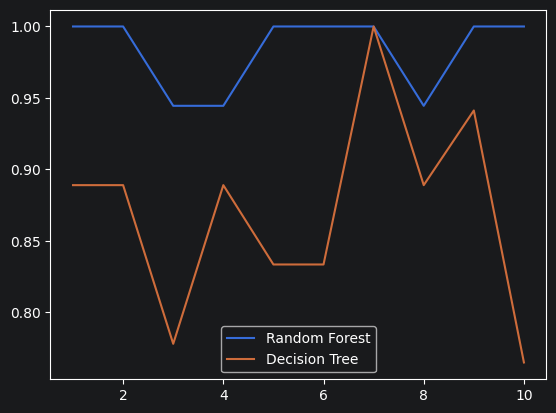

In [29]:
#随机森林和决策树在一组交叉验证下的效果对比
#交叉验证：数据集划分为n份，依次取每一份做测试集，每n-1份做训练集，多次训练模型以观测模型稳定性的方法
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

rfc=RandomForestClassifier(n_estimators=25)
rfc_s=cross_val_score(rfc,wine.data,wine.target,cv=10)

clf=DecisionTreeClassifier()
clf_s=cross_val_score(clf,wine.data,wine.target,cv=10)

plt.plot(range(1,11),rfc_s,label='Random Forest')
plt.plot(range(1,11),clf_s,label='Decision Tree')
plt.legend()
plt.show()

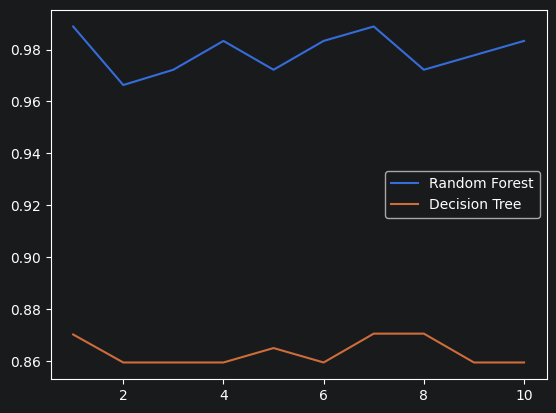

In [30]:
#随机森林和决策树在十组交叉验证下的效果对比
rfc_l=[]
clf_l=[]

for i in range(10):
    rfc=RandomForestClassifier(n_estimators=25)
    rfc_s=cross_val_score(rfc,wine.data,wine.target,cv=10).mean()
    rfc_l.append(rfc_s)
    clf=DecisionTreeClassifier()
    clf_s=cross_val_score(clf,wine.data,wine.target,cv=10).mean()
    clf_l.append(clf_s)

plt.plot(range(1,11),rfc_l,label='Random Forest')
plt.plot(range(1,11),clf_l,label='Decision Tree')
plt.legend()
plt.show()

### 重要属性和接口
.estimators_

.oob_score_

.feature_importances_

In [31]:
rfc=RandomForestClassifier(n_estimators=25)
rfc=rfc.fit(Xtrain,Ytrain)
rfc.score(Xtest,Ytest)

rfc.feature_importances_
rfc.apply(Xtest)
rfc.predict(Xtest)
rfc.predict_proba(Xtest)

array([[0.  , 0.16, 0.84],
       [0.  , 0.88, 0.12],
       [0.96, 0.04, 0.  ],
       [1.  , 0.  , 0.  ],
       [0.04, 0.96, 0.  ],
       [0.  , 0.04, 0.96],
       [0.  , 0.12, 0.88],
       [0.2 , 0.8 , 0.  ],
       [0.2 , 0.8 , 0.  ],
       [0.08, 0.92, 0.  ],
       [0.04, 0.96, 0.  ],
       [0.72, 0.24, 0.04],
       [1.  , 0.  , 0.  ],
       [0.92, 0.04, 0.04],
       [1.  , 0.  , 0.  ],
       [0.72, 0.28, 0.  ],
       [0.08, 0.88, 0.04],
       [0.68, 0.28, 0.04],
       [0.04, 0.12, 0.84],
       [0.04, 0.96, 0.  ],
       [0.08, 0.24, 0.68],
       [0.16, 0.8 , 0.04],
       [0.  , 0.96, 0.04],
       [0.  , 0.92, 0.08],
       [0.36, 0.6 , 0.04],
       [0.04, 0.96, 0.  ],
       [0.28, 0.68, 0.04],
       [0.6 , 0.4 , 0.  ],
       [0.  , 0.  , 1.  ],
       [0.96, 0.04, 0.  ],
       [0.08, 0.84, 0.08],
       [0.  , 0.28, 0.72],
       [0.08, 0.92, 0.  ],
       [1.  , 0.  , 0.  ],
       [0.08, 0.04, 0.88],
       [0.  , 0.16, 0.84],
       [0.  , 1.  , 0.  ],
 

### 调参
#### 泛化误差
用来衡量模型在未知数据上的准确率的指标，叫泛化误差。当模型太复杂，模型就会过拟合，泛化能力就不够，泛化误差大；当模型太简单，模型就会欠拟合，拟合能力不够，误差也会大。只有当模型复杂度刚刚好才能达到泛化误差最小目标。

调参顺序：

n_estimators：提升至平稳，n.estimators增大，不影响单个模型的复杂度。

max depth：有增有减，默认最大深度，即最高复杂度，向复杂度降低的方向调参，max_depthy越小，模型更简单，且向图像的左边移动

min samples_leaf：有增有减，默认最小限制1，即最高复杂度，向复杂度降低的方向调參
min_samples_leaf越大，模型更简单，且向图像的左边移动

min_samples_split：有增有减，默认最小限制2，即最高复杂度，向复杂度降低的方向调参
min.samples_split更大，模型更简单，且向图像的左边移动

max_features：有增有减，默认auto，是特征总数的开平方，位于中间复杂度，既可以
向复杂度升高的方向，也可以向复杂應降低的方向洞参。
max_features越小,， 模型更简单，图像左移；
max_features越大, 模型更复杂，图像右移。
max features.是唯一的，既能让模型更简单，也轮够让模型更复杂的参数，所以在调整这个参数的时候，需要考虑我们调参的方向

criterion：有增邮件，一般使用gini

### 实例：随机森林在乳腺癌数据上的调参

In [32]:
#关闭可视化渲染
import sklearn
sklearn.set_config(display="text")
# 需要导入的库
from sklearn.datasets import load_breast_cancer #导入乳腺癌数据
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV #网格搜索
from sklearn.model_selection import cross_val_score #交叉验证
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [33]:
data=load_breast_cancer()

In [34]:
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [35]:
data.data.shape

(569, 30)

In [36]:
data.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

In [37]:
# 建模
rfc=RandomForestClassifier(n_estimators=100,random_state=90) #实例化，建立100棵树的随机森林
score_pre=cross_val_score(rfc,data.data,data.target,cv=10).mean() #交叉验证10次，求平均值
score_pre

np.float64(0.9648809523809524)

0.9631265664160402 71


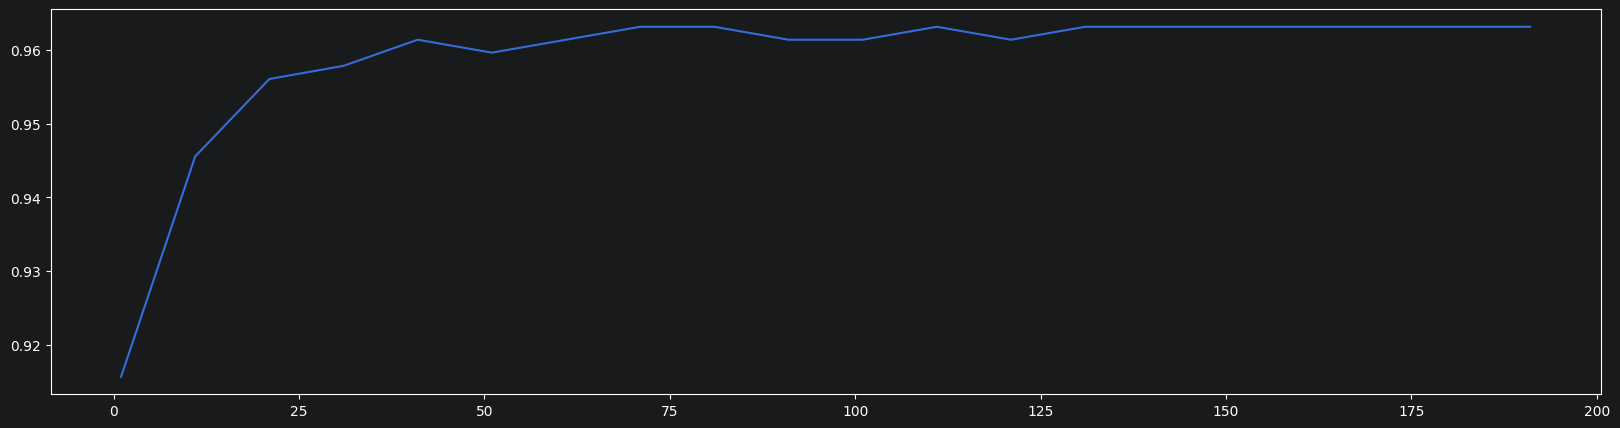

In [38]:
# 随机森林第一步：无论如何先来调n_estimators
scorel=[]
for i in range(0,200,10):
    rfc=RandomForestClassifier(n_estimators=i+1,
                               n_jobs=-1,
                               random_state=90)
    score=cross_val_score(rfc,data.data,data.target,cv=10).mean()
    scorel.append(score)
print(max(scorel),(scorel.index(max(scorel))*10)+1)
plt.figure(figsize=[20,5])
plt.plot(range(1,201,10),scorel)
plt.show()
#list.index([object]) 返回这个object在列表list中的索引

0.9666353383458647 73


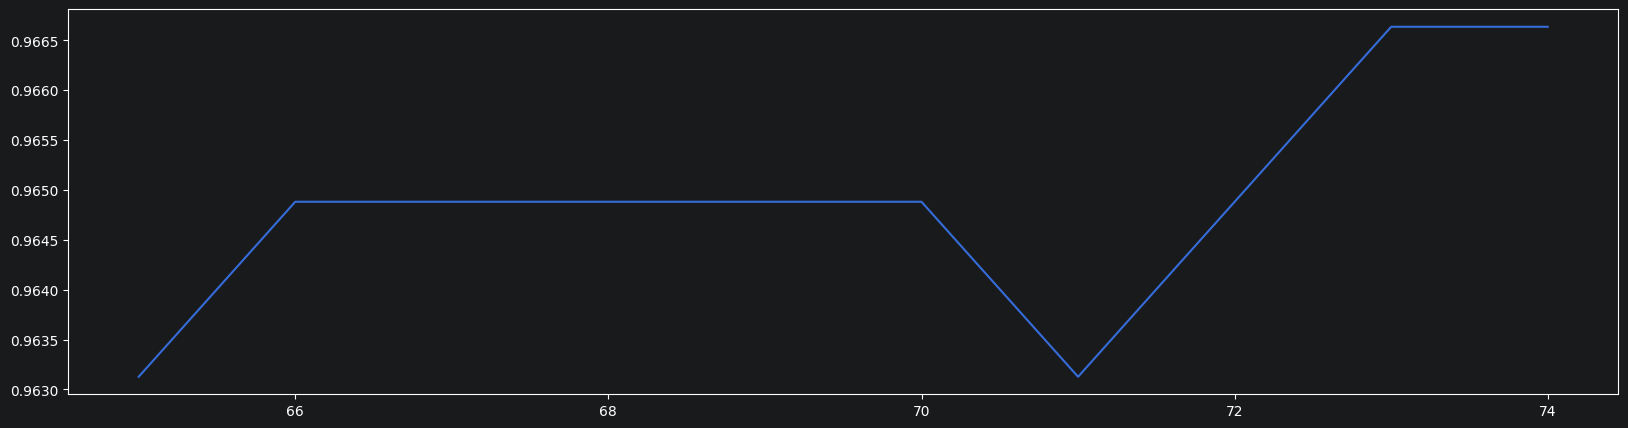

In [39]:
# 在确定好的范围内，进一步细化学习曲线
scorel=[]
for i in range(65,75):
    rfc=RandomForestClassifier(n_estimators=i,
                               n_jobs=-1,
                               random_state=90)
    score=cross_val_score(rfc,data.data,data.target,cv=10).mean()
    scorel.append(score)
print(max(scorel),([*range(65,75)][scorel.index(max(scorel))]))
plt.figure(figsize=[20,5])
plt.plot(range(65,75),scorel)
plt.show()

In [54]:
# 为网格搜索做准备，书写网格搜索的参数
'''
有一些参数是没有参照的，很难说清一个范围，这种情况下我们使用学习曲线，看趋势从曲线跑出的结果中选取一个更小的区间，在跑曲线。

有一些参数是可以找到一个范围的，或者知道它的取值或随着它的取值，模型的整体准确率会如何变化，这样的参数我们就可以直接跑网格搜索。
'''

'\n有一些参数是没有参照的，很难说清一个范围，这种情况下我们使用学习曲线，看趋势从曲线跑出的结果中选取一个更小的区间，在跑曲线。\n\n有一些参数是可以找到一个范围的，或者知道它的取值或随着它的取值，模型的整体准确率会如何变化，这样的参数我们就可以直接跑网格搜索。\n'

In [40]:
# 开始按照参数对模型整体准确率的影响程度进行调参，首先调整max_depth
param_grid={'max_depth':np.arange(1,20,1)}
rfc=RandomForestClassifier(n_estimators=39,
                           random_state=90) #实例化
GS=GridSearchCV(rfc,param_grid,cv=10) #网格搜索，导入实例化好的模型，调整参数，交叉验证10次
GS.fit(data.data,data.target)

GridSearchCV(cv=10,
             estimator=RandomForestClassifier(n_estimators=39, random_state=90),
             param_grid={'max_depth': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19])})

In [41]:
GS.best_params_

{'max_depth': np.int64(6)}

In [42]:
GS.best_score_

np.float64(0.9631265664160402)

In [43]:
# 调整max_features
param_grid={'max_features':np.arange(2,12,1)}
rfc=RandomForestClassifier(n_estimators=39,
                           random_state=90) #实例化
GS=GridSearchCV(rfc,param_grid,cv=10) #网格搜索，导入实例化好的模型，调整参数，交叉验证10次
GS.fit(data.data,data.target)

GridSearchCV(cv=10,
             estimator=RandomForestClassifier(n_estimators=39, random_state=90),
             param_grid={'max_features': array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11])})

In [44]:
GS.best_params_

{'max_features': np.int64(6)}

In [45]:
GS.best_score_

np.float64(0.968421052631579)

In [46]:
# 调整min_samples_leaf
param_grid={'min_samples_leaf':np.arange(1,1+10,1)}
rfc=RandomForestClassifier(n_estimators=39,
                           random_state=90) #实例化
GS=GridSearchCV(rfc,param_grid,cv=10) #网格搜索，导入实例化好的模型，调整参数，交叉验证10次
GS.fit(data.data,data.target)

GridSearchCV(cv=10,
             estimator=RandomForestClassifier(n_estimators=39, random_state=90),
             param_grid={'min_samples_leaf': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])})

In [47]:
GS.best_params_

{'min_samples_leaf': np.int64(4)}

In [48]:
GS.best_score_

np.float64(0.9613721804511279)

In [49]:
# 调整完毕，总结出模型的最佳参数
rfc=RandomForestClassifier(n_estimators=39,random_state=90)
score=cross_val_score(rfc,data.data,data.target,cv=10).mean()

In [50]:
score

np.float64(0.9578634085213033)

In [51]:
score-score_pre

np.float64(-0.007017543859649145)

总结：

1）调整n_estimators

2）调整max_depth,通过结果判断下一步应该调整的参数和方向

### 混淆矩阵
TP预测为正且预测结果正确
FP预测为负且预测结果正确
FN预测为负且预测结果错误
TN预测为正且预测结果错误

#### 准确率
总样本中预测对了多少

#### 精确率（查准率）
预测为正的样本中实际为正的有多少

#### 召回率
实际为正的样本中有多少被预测为正了

#### F1
让一个评价指标中，既能体现查准率又能体现召回率
F1=2*精确率*召回率/（精确率+召回率）

### KNN
找离这个样本最近的 K 个邻居，邻居大多数是什么类别，就预测它是什么类别.

## sklearn中的数据预处理和特征工程
数据挖掘的五大特征：

1.获取数据

2.数据预处理

从数据中检测、纠正或删除损坏，不准确或不适于模型记录的过程。

目的：让数据适应模型，匹配模型的需求。

3.特征工程

将原始数据转换为更能代表预测模型的潜在问题的特征的过程。

目的：降低计算成本；提升模型上限。

4.建模，测试模型并预测结果

5.上线，验证模型效果

### 数据预处理 Preprocessing & Impute
#### 数据无量纲化
把不同规格的数据转化到统一规格，或将不同分布的数据转化到伯格特定的分布。在梯度和矩阵为核心的算法中，譬如逻辑回归、支持向量机、神经网络等，无量纲化可以加快求解速度；在距离类模型中，譬如k近邻、k-means，无量纲化可以提升模型的精度。

数据的无量纲化可以是线性，也可以是非线性。线性的无量纲化包括中心化和缩放处理。中心化的本质是加减一个固定值让图像平移；缩放的本质是除以一个固定值，让数据固定在某个范围中，取对数也是一种缩放处理。

##### preprocessing.MinMaxScaler
数据归一化（Normalization,又称Min-Max Scaling）：数据（x）按最小值中心化后，再按极差（最大值-最小值）缩放，数据移动了最小值个单位，并且会被收敛到[0,1]之间的过程。

In [52]:
from sklearn.preprocessing import MinMaxScaler
data=[[-1,2],[-0.5,6],[0,10],[1,18]]
import pandas as pd
pd.DataFrame(data)

,0,1
0,-1.0,2
1,-0.5,6
2,0.0,10
3,1.0,18


In [53]:
#实现归一化
scaler=MinMaxScaler() #实例化
scaler=scaler.fit(data) #fit,在这里本质是生成min(x)和max(x)
result=scaler.transform(data) #通过接口导出结果
result

array([[0.  , 0.  ],
       [0.25, 0.25],
       [0.5 , 0.5 ],
       [1.  , 1.  ]])

In [54]:
result_=scaler.fit_transform(data) #训练和导出结果一步达成
result_

array([[0.  , 0.  ],
       [0.25, 0.25],
       [0.5 , 0.5 ],
       [1.  , 1.  ]])

In [55]:
scaler.inverse_transform(result) #将归一化后的结果逆转

array([[-1. ,  2. ],
       [-0.5,  6. ],
       [ 0. , 10. ],
       [ 1. , 18. ]])

In [56]:
#使用MinMaxScaler的参数feature_range实现将数据归一化到[0,1]以外的范围中
data=[[-1,2],[-0.5,6],[0,10],[1,18]]

scaler=MinMaxScaler(feature_range=(5,10)) #实例化
result=scaler.fit_transform(data) #fit_transform一步导出结果
result

array([[ 5.  ,  5.  ],
       [ 6.25,  6.25],
       [ 7.5 ,  7.5 ],
       [10.  , 10.  ]])

In [60]:
#当x中的特征数量非常多的时候，fit会报错并表示，数据量太大了我计算不了
#此时使用partial_fit作为训练接口
#scaler=scaler.partial_fit(data)

In [57]:
#用numpy实现归一化
import numpy as np
x=np.array([[-1,2],[-0.5,6],[0,10],[1,18]])

#归一化
x_nor=(x-x.min(axis=0)/(x.max(axis=0)-x.min(axis=0)))
x_nor

array([[-0.5  ,  1.875],
       [ 0.   ,  5.875],
       [ 0.5  ,  9.875],
       [ 1.5  , 17.875]])

In [58]:
#逆转归一化
x_returned=x_nor*(x.max(axis=0)-x.min(axis=0))+x.min(axis=0)
x_returned

array([[ -2.,  32.],
       [ -1.,  96.],
       [  0., 160.],
       [  2., 288.]])

##### preprocessing.StandarScaler
数据标准化：数据(x)按均值中心化后，再按标准差缩放，数据就会服从为均值为0，方差为1的正态分布的过程。

In [59]:
from sklearn.preprocessing import StandardScaler
data=[[-1,2],[-0.5,6],[0,10],[1,18]]

In [60]:
scaler=StandardScaler() #实例化
scaler.fit(data) #fit,本质是生成均值和方差

StandardScaler()

In [61]:
scaler.mean_ #查看均值的属性mean_

array([-0.125,  9.   ])

In [62]:
scaler.var_ #查看方差的属性var_

array([ 0.546875, 35.      ])

In [63]:
x_std=scaler.transform(data) #通过接口导出结果

In [64]:
x_std

array([[-1.18321596, -1.18321596],
       [-0.50709255, -0.50709255],
       [ 0.16903085,  0.16903085],
       [ 1.52127766,  1.52127766]])

In [65]:
x_std.mean() #导出的结果是一个数组，用mean()查看均值

np.float64(0.0)

In [66]:
x_std.std() #用std()查看方案

np.float64(1.0)

In [67]:
scaler.fit_transform(data) #使用fit_transform(data)一步达成结果
scaler.inverse_transform(x_std) #使用inverse_transform逆转标准化

array([[-1. ,  2. ],
       [-0.5,  6. ],
       [ 0. , 10. ],
       [ 1. , 18. ]])

对于StandScaler和MinMaxScaler来说，空值NaN会被当做缺失值，在fit的时候忽略，在transform的时候保持缺失NaN的状态显示。在fit接口中，依然只允许导入至少二维数组，一维数组导入会报错。

大多数机器学习算法中，会选择StandScaler来进行特征放缩，因为MinMaxScaler对异常值非常敏感。

#### 缺失值
数字挖掘中，有重要字段缺失值很多，但又不能舍弃，数据预处理中非常重要一项就是处理缺失值。

In [68]:
import pandas as pd
data=pd.read_csv(r"titanic.csv",index_col=0)
data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


##### impute.Simplelmputer
missing_values:告诉Simplelmputer，数据中缺失值长什么样子，默认空值np.nan

strategy:我们填补缺失值的策略，默认均值。输入“mean”使用均值填补（仅对数值型特征可用）；输入“median”用中值填补（仅对数值型特征可用）；输入“most_frequent”用众数填补（对数值型和字符型特征都可用）；输入“constant”表示请参考参数“fill_value”中的值（对数值型和字符型特征都可用）

fill_value:当参数startegy为“constant”的时候可用，可输入字符串或数字表示要填充的值，常用0

copy:默认为True，将创建特征矩阵的副本，反之则会将缺失值填补到原本的特征矩阵中去。

In [69]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


In [70]:
#填补年龄
Age=data.loc[:,"Age"].values.reshape(-1,1) #sklearn当中特征矩阵必须是二维
Age[:20]

array([[22.],
       [38.],
       [26.],
       [35.],
       [35.],
       [nan],
       [54.],
       [ 2.],
       [27.],
       [14.],
       [ 4.],
       [58.],
       [20.],
       [39.],
       [14.],
       [55.],
       [ 2.],
       [nan],
       [31.],
       [nan]])

In [71]:
from sklearn.impute import SimpleImputer
imp_mean=SimpleImputer() #实例化，默认均值填补
imp_median=SimpleImputer(strategy="median") #用中位数填补
imp_0=SimpleImputer(strategy="constant",fill_value=0) #用0填补

In [72]:
imp_mean=imp_mean.fit_transform(Age) #fit_transform一步完成调取结果
imp_median=imp_median.fit_transform(Age)
imp_0=imp_0.fit_transform(Age)

In [73]:
imp_mean[:20]

array([[22.        ],
       [38.        ],
       [26.        ],
       [35.        ],
       [35.        ],
       [29.69911765],
       [54.        ],
       [ 2.        ],
       [27.        ],
       [14.        ],
       [ 4.        ],
       [58.        ],
       [20.        ],
       [39.        ],
       [14.        ],
       [55.        ],
       [ 2.        ],
       [29.69911765],
       [31.        ],
       [29.69911765]])

In [74]:
imp_median[:20]

array([[22.],
       [38.],
       [26.],
       [35.],
       [35.],
       [28.],
       [54.],
       [ 2.],
       [27.],
       [14.],
       [ 4.],
       [58.],
       [20.],
       [39.],
       [14.],
       [55.],
       [ 2.],
       [28.],
       [31.],
       [28.]])

In [75]:
imp_0[:20]

array([[22.],
       [38.],
       [26.],
       [35.],
       [35.],
       [ 0.],
       [54.],
       [ 2.],
       [27.],
       [14.],
       [ 4.],
       [58.],
       [20.],
       [39.],
       [14.],
       [55.],
       [ 2.],
       [ 0.],
       [31.],
       [ 0.]])

In [76]:
#使用中位数填补Age
data.loc[:,"Age"]=imp_median

In [77]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       891 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


In [78]:
#用众数填补Embarked
Embarked=data.loc[:,"Embarked"].values.reshape(-1,1)
imp_mode=SimpleImputer(strategy="most_frequent")
data.loc[:,"Embarked"]=imp_mode.fit_transform(Embarked)

In [79]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       891 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  891 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


用Pandas和Numpy进行填补

In [80]:
import pandas as pd
import numpy as np
data=pd.read_csv(r"titanic.csv",index_col=0)
data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [81]:
data.loc[:,"Age"]=data.loc[:,"Age"].fillna(data.loc[:,"Age"].median()) #.fillna在DataFrame中直接进行填补

In [82]:
data.dropna(axis=0,inplace=True) #.dropna(axis=0)删除所有有缺失值的行，.dropna(axis=1)删除所有有缺失值的列
#参数inplace,为True表示在原数据集上进行修改，为False表示生成一个复制对象，不修改原数据，默认False

#### 处理分类型特征：编码与哑变量
为了让数据适应算法和库，我们将数据进行编码，就是将文字型数据转换为数值型。

##### preprocessing.LabelEncoder
标签专用，能将分类转换为分类数值

In [83]:
from sklearn.preprocessing import LabelEncoder
y=data.iloc[:,-1] #要输入的是标签，不是特征矩阵，所以允许一维

In [84]:
le=LabelEncoder() #实例化
le=le.fit(y) #导入数据
label=le.transform(y) #transform接口调取结果

In [85]:
label

array([0, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 2, 2, 2, 2, 2, 2, 0, 0, 2, 2, 0,
       2, 2, 0, 2, 2, 0, 2, 2, 2, 2, 0, 0, 2, 2, 2, 0, 0, 2, 0, 0, 0, 2,
       2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 0, 0, 2, 2, 0, 1, 2, 0, 0,
       0, 0, 2, 0, 0, 2, 0, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 2,
       0, 2, 1, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 2, 0, 2, 2, 2, 2, 0, 2, 2, 0, 2, 0, 0, 0, 2, 2, 2, 2, 0, 0,
       2, 0, 0, 0, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 2, 2, 2, 0, 0, 2, 2,
       0, 2, 0, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 2, 1, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 2, 2, 2, 2, 2,
       2, 0, 2, 0])

In [86]:
le.classes_ #属性，classes_查看标签中究竟有多少类别

array(['C', 'Q', 'S'], dtype=object)

In [87]:
le.fit_transform(y) #也可以fit_transform一步到位，但此之后不能导入属性
#属性只能在实例化和fit之后

array([0, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 2, 2, 2, 2, 2, 2, 0, 0, 2, 2, 0,
       2, 2, 0, 2, 2, 0, 2, 2, 2, 2, 0, 0, 2, 2, 2, 0, 0, 2, 0, 0, 0, 2,
       2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 0, 0, 2, 2, 0, 1, 2, 0, 0,
       0, 0, 2, 0, 0, 2, 0, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 2,
       0, 2, 1, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 2, 0, 2, 2, 2, 2, 0, 2, 2, 0, 2, 0, 0, 0, 2, 2, 2, 2, 0, 0,
       2, 0, 0, 0, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 2, 2, 2, 0, 0, 2, 2,
       0, 2, 0, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 2, 1, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 2, 2, 2, 2, 2,
       2, 0, 2, 0])

In [88]:
le.inverse_transform(label) #使用inverse_transform可以逆转

array(['C', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'C', 'C', 'C', 'S', 'S',
       'S', 'S', 'S', 'S', 'C', 'C', 'S', 'S', 'C', 'S', 'S', 'C', 'S',
       'S', 'C', 'S', 'S', 'S', 'S', 'C', 'C', 'S', 'S', 'S', 'C', 'C',
       'S', 'C', 'C', 'C', 'S', 'S', 'Q', 'S', 'S', 'S', 'S', 'S', 'S',
       'S', 'S', 'C', 'S', 'S', 'C', 'C', 'S', 'S', 'C', 'Q', 'S', 'C',
       'C', 'C', 'C', 'S', 'C', 'C', 'S', 'C', 'S', 'S', 'S', 'C', 'S',
       'S', 'S', 'S', 'S', 'S', 'C', 'C', 'C', 'C', 'S', 'C', 'S', 'Q',
       'S', 'S', 'S', 'S', 'S', 'S', 'S', 'C', 'C', 'S', 'S', 'S', 'S',
       'C', 'S', 'C', 'S', 'C', 'S', 'C', 'S', 'S', 'C', 'S', 'S', 'S',
       'S', 'C', 'S', 'S', 'C', 'S', 'C', 'C', 'C', 'S', 'S', 'S', 'S',
       'C', 'C', 'S', 'C', 'C', 'C', 'S', 'S', 'S', 'S', 'S', 'S', 'C',
       'C', 'C', 'C', 'C', 'S', 'S', 'S', 'C', 'C', 'S', 'S', 'C', 'S',
       'C', 'S', 'S', 'C', 'S', 'S', 'S', 'C', 'S', 'S', 'S', 'C', 'S',
       'S', 'C', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'Q', 'S', 'S

##### preprocessing.OrdinalEncoder
特征专用，能将分类特征转换为分类数值

In [89]:
from sklearn.preprocessing import OrdinalEncoder
#接口categories_对应LabelEncoder的接口classes_，一模一样的功能
data_=data.copy()

In [90]:
data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S
12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S


In [91]:
OrdinalEncoder().fit(data_.iloc[:,[3,10]]).categories_

[array(['female', 'male'], dtype=object), array(['C', 'Q', 'S'], dtype=object)]

In [129]:
data_.iloc[:,[3,10]]=OrdinalEncoder().fit_transform(data_.iloc[:,[3,10]])

TypeError: Invalid value '[0. 0. 1. 0. 0. 1. 1. 1. 0. 0. 1. 1. 1. 0. 1. 0. 1. 1. 1. 1. 1. 1. 0. 1.
 0. 0. 1. 1. 1. 0. 0. 1. 1. 0. 1. 1. 1. 0. 0. 0. 1. 0. 0. 1. 0. 1. 1. 0.
 1. 0. 1. 1. 0. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 1. 1. 0. 1. 1. 0. 0. 1. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0. 1.
 1. 1. 1. 1. 1. 0. 1. 1. 0. 1. 1. 0. 1. 1. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1.
 1. 0. 0. 1. 1. 0. 0. 0. 1. 0. 0. 1. 0. 1. 0. 1. 0. 0. 1. 1. 0. 1. 1. 0.
 1. 1. 1. 1. 0. 1. 1. 1. 0. 1. 1. 1. 0. 1. 1. 0. 1. 1. 1. 0. 0. 1. 0. 1.
 1. 1. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0. 1. 1. 0. 1. 1. 0. 1. 0. 0. 0. 1.
 0. 0. 1. 0. 1. 0. 1. 0. 0. 1.]' for dtype 'str'

In [92]:
data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S
12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S


##### preprocessing.OneHotEncoder
独热编码，创建哑变量

In [93]:
data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S
12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S


In [94]:
from sklearn.preprocessing import OneHotEncoder
x=data.iloc[:,[3,10]]

In [95]:
enc=OneHotEncoder(categories='auto').fit(x)
result=enc.transform(x).toarray()

In [96]:
result

array([[1., 0., 1., 0., 0.],
       [1., 0., 0., 0., 1.],
       [0., 1., 0., 0., 1.],
       ...,
       [1., 0., 1., 0., 0.],
       [1., 0., 0., 0., 1.],
       [0., 1., 1., 0., 0.]], shape=(202, 5))

In [97]:
#一步到位
OneHotEncoder(categories='auto').fit_transform(x).toarray()

array([[1., 0., 1., 0., 0.],
       [1., 0., 0., 0., 1.],
       [0., 1., 0., 0., 1.],
       ...,
       [1., 0., 1., 0., 0.],
       [1., 0., 0., 0., 1.],
       [0., 1., 1., 0., 0.]], shape=(202, 5))

In [98]:
#还原
pd.DataFrame(enc.inverse_transform(result))

,0,1
0,female,C
1,female,S
2,male,S
3,female,S
4,female,S
...,...,...
197,female,S
198,male,S
199,female,C
200,female,S


In [99]:
enc.get_feature_names_out()

array(['Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S'],
      dtype=object)

In [100]:
result.shape

(202, 5)

In [101]:
#axis=1，表示跨行进行合并，也就是将两表左右相连，如果是axis=0，就是将两表上下相连
newdata=pd.concat([data,pd.DataFrame(result)],axis=1)

In [102]:
newdata.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,0,1,2,3,4
2,1.0,1.0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1.0,0.0,PC 17599,71.2833,C85,C,0.0,1.0,0.0,0.0,1.0
4,1.0,1.0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1.0,0.0,113803,53.1000,C123,S,1.0,0.0,0.0,0.0,1.0
7,0.0,1.0,"McCarthy, Mr. Timothy J",male,54.0,0.0,0.0,17463,51.8625,E46,S,0.0,1.0,0.0,0.0,1.0
11,1.0,3.0,"Sandstrom, Miss. Marguerite Rut",female,4.0,1.0,1.0,PP 9549,16.7000,G6,S,0.0,1.0,0.0,0.0,1.0
12,1.0,1.0,"Bonnell, Miss. Elizabeth",female,58.0,0.0,0.0,113783,26.5500,C103,S,0.0,1.0,0.0,0.0,1.0


In [103]:
newdata.drop(["Sex","Embarked"],axis=1,inplace=True)

In [104]:
df_onehot=pd.DataFrame(result,columns=enc.get_feature_names_out())
newdata=pd.concat([data,df_onehot],axis=1)
newdata.drop(["Sex","Embarked"],axis=1,inplace=True)

In [105]:
newdata.head()

,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
2,1.0,1.0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1.0,0.0,PC 17599,71.2833,C85,0.0,1.0,0.0,0.0,1.0
4,1.0,1.0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1.0,0.0,113803,53.1000,C123,1.0,0.0,0.0,0.0,1.0
7,0.0,1.0,"McCarthy, Mr. Timothy J",54.0,0.0,0.0,17463,51.8625,E46,0.0,1.0,0.0,0.0,1.0
11,1.0,3.0,"Sandstrom, Miss. Marguerite Rut",4.0,1.0,1.0,PP 9549,16.7000,G6,0.0,1.0,0.0,0.0,1.0
12,1.0,1.0,"Bonnell, Miss. Elizabeth",58.0,0.0,0.0,113783,26.5500,C103,0.0,1.0,0.0,0.0,1.0


#### 二值化与分段
##### sklearn.preprocessing.Binarizer
根据阈值将数据二值化（将特征值设置为0或1），用于处理连续型变量。大于阈值的值映射为1，小于阈值的值映射为0.默认阈值为0时，特征所有的正值都映射到1。

In [106]:
# 将年龄二值化
data_2=data.copy()

In [124]:
from sklearn.preprocessing import Binarizer
x=data_2.iloc[:5,3].values.reshape(-1,1) #类为特征专用，所以不能使用一维数组

In [125]:
transformer=Binarizer(threshold=30).fit_transform(x)
transformer

ValueError: could not convert string to float: 'female'

##### preprocessing.KBinsDiscretizer
这是将连续型变量划分为分类变量的类，能将连续型变量排序后按顺序分箱后编码。

n_bins:每个特征中分箱的个数，默认5，一次会被运用到所有导入的特征。

encode:编码的方式，默认“onehot”。

“onehot”：做哑变量，之后返回一个稀疏矩阵，每一列是一个特征中的一个类别，含有该类别的样本表示为1，不含的表示为0。

“ordinal”：每个特征的每个箱都被编码为一个整数，返回每一列是一个特征，每个特征下含有不同整数编码的箱的矩阵。

“onehot_dense”：做哑变量，之后返回一个密集数组。

strategy:用来定义箱宽的方式，默认“quantile”。

“uniform”：表示等宽分箱，即每个特征中的每个箱的最大值之间的差为（特征.max()-特征.min()）/(n_bins)

“quantile”：表示等位分箱，即每个特征中的每个箱内的样本数量都相同。

“kmeans”：表示按聚类分箱，每个箱中的值到最近的一维k均值聚类的簇心的距离都相同。

In [126]:
from sklearn.preprocessing import KBinsDiscretizer
x=data.iloc[:,3].values.reshape(-1,1)

In [128]:
est=KBinsDiscretizer(n_bins=3,encode='ordinal',strategy='uniform')
est.fit_transform(x)

ValueError: could not convert string to float: 'female'

In [129]:
# 查看转换后分的箱：变成了一列中的三箱
set(est.fit_transform(x).ravel())
est=KBinsDiscretizer(n_bins=3,encode='onehot',strategy='uniform')
# 查看转换后的分箱：变成了哑变量
est.fit_transform(x).toarray()

ValueError: could not convert string to float: 'female'